# Customer Churn - Model Training (EBM, first 30 days)

Explainable Boosting Machine trained on features from the first 30 days of usage (`train_features_30d.csv`).

Dataset: [Real-World Churn (Kaggle)](https://www.kaggle.com/datasets/lasaljaywardena/real-world-churn/data)

## 1. Setup

In [1]:
import os
import json
import time
from datetime import datetime

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

from interpret.glassbox import ExplainableBoostingClassifier
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_score, recall_score, accuracy_score, confusion_matrix, classification_report, roc_curve, precision_recall_curve

In [2]:
DATA_DIR = 'data/processed'
MODEL_DIR = 'models'
FIG_DIR = 'figures'
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

SEED = 42
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

## 2. Load data

In [3]:
train_df = pd.read_csv(DATA_DIR + '/train_features_30d.csv')
test_df = pd.read_csv(DATA_DIR + '/test_features_30d.csv')
print(train_df.shape, test_df.shape)

(52004, 51) (13001, 51)


In [4]:
# train file is sorted by churn, so shuffle it
train_df = train_df.sample(frac=1, random_state=SEED).reset_index(drop=True)

feature_cols = [c for c in train_df.columns if c not in ['customer_id', 'churn']]

X_train, y_train = train_df[feature_cols], train_df.churn
X_test, y_test = test_df[feature_cols], test_df.churn

print(len(feature_cols), 'features')
print(y_train.mean(), y_test.mean())

49 features
0.23117452503653566 0.2290593031305284


## 3. Train / validation split

In [5]:
# 20% of train kept aside to compare the default and tuned models
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=SEED)
print(X_tr.shape, X_val.shape)

(41603, 49) (10401, 49)


In [6]:
def get_metrics(y, score):
    pred = (score >= 0.5).astype(int)
    return {
        'accuracy': accuracy_score(y, pred),
        'precision': precision_score(y, pred),
        'recall': recall_score(y, pred),
        'f1': f1_score(y, pred),
        'roc_auc': roc_auc_score(y, score),
        'pr_auc': average_precision_score(y, score),
    }

## 4. Default EBM

In [7]:
ebm_base = ExplainableBoostingClassifier(random_state=SEED, n_jobs=-1)

t = time.time()
ebm_base.fit(X_tr, y_tr)
print('took', round(time.time() - t), 's')

took 425 s


In [8]:
base_train = get_metrics(y_tr, ebm_base.predict_proba(X_tr)[:, 1])
base_val = get_metrics(y_val, ebm_base.predict_proba(X_val)[:, 1])
pd.DataFrame({'train': base_train, 'validation': base_val}).round(4)

,train,validation
accuracy,0.9842,0.9623
precision,0.9723,0.9299
recall,0.9588,0.9052
f1,0.9655,0.9174
roc_auc,0.9985,0.9915
pr_auc,0.9955,0.9758


## 5. Tuning

In [9]:
# random search on a 20k sample with 4 outer bags (default is 14), ebm is slow on the full set
X_tune, _, y_tune, _ = train_test_split(X_tr, y_tr, train_size=20000, stratify=y_tr, random_state=SEED)

ebm_params = {
    'learning_rate': [0.005, 0.015, 0.03, 0.06],
    'max_bins': [64, 256, 1024],
    'interactions': [0, 5, 10, 20],
    'max_leaves': [2, 3],
    'min_samples_leaf': [2, 10, 50],
    'smoothing_rounds': [0, 75, 200],
}
ebm_search = RandomizedSearchCV(ExplainableBoostingClassifier(outer_bags=4, max_rounds=5000, random_state=SEED, n_jobs=-1),
                                ebm_params, n_iter=16, scoring='neg_log_loss', cv=cv,
                                random_state=SEED, n_jobs=1, verbose=1)

t = time.time()
ebm_search.fit(X_tune, y_tune)
print('took', round(time.time() - t), 's')
print(ebm_search.best_params_, -ebm_search.best_score_)

Fitting 3 folds for each of 16 candidates, totalling 48 fits


took 1367 s
{'smoothing_rounds': 75, 'min_samples_leaf': 50, 'max_leaves': 2, 'max_bins': 1024, 'learning_rate': 0.015, 'interactions': 20} 0.10927970643692113


In [10]:
res = pd.DataFrame(ebm_search.cv_results_)
res['log_loss'] = -res.mean_test_score
cols = [c for c in res.columns if c.startswith('param_')]
res[cols + ['log_loss', 'mean_fit_time']].sort_values('log_loss').round(4)

,param_smoothing_rounds,param_min_samples_leaf,param_max_leaves,param_max_bins,param_learning_rate,param_interactions,log_loss,mean_fit_time
15,75,50,2,1024,0.015,20,0.1093,40.2396
14,75,50,3,256,0.005,20,0.1094,64.1102
11,75,10,2,256,0.030,20,0.1120,31.7437
8,200,50,3,1024,0.005,10,0.1134,84.1210
6,200,50,3,1024,0.030,10,0.1139,8.3484
1,0,2,2,256,0.015,20,0.1148,28.8866
13,200,10,3,256,0.005,10,0.1150,38.1940
9,75,10,3,256,0.060,10,0.1160,28.1557
2,200,10,2,1024,0.060,10,0.1161,8.5376
12,75,2,2,1024,0.060,10,0.1196,15.4013


In [11]:
best_params = ebm_search.best_params_

ebm_tuned = ExplainableBoostingClassifier(**best_params, random_state=SEED, n_jobs=-1)
ebm_tuned.fit(X_tr, y_tr)

tuned_train = get_metrics(y_tr, ebm_tuned.predict_proba(X_tr)[:, 1])
tuned_val = get_metrics(y_val, ebm_tuned.predict_proba(X_val)[:, 1])
pd.DataFrame({'default train': base_train, 'default val': base_val,
              'tuned train': tuned_train, 'tuned val': tuned_val}).round(4)

,default train,default val,tuned train,tuned val
accuracy,0.9842,0.9623,0.9763,0.9640
precision,0.9723,0.9299,0.9554,0.9341
recall,0.9588,0.9052,0.9414,0.9085
f1,0.9655,0.9174,0.9483,0.9211
roc_auc,0.9985,0.9915,0.9965,0.9912
pr_auc,0.9955,0.9758,0.9895,0.9752


## 6. Final model

In [12]:
# refit on the full train set
ebm_model = ExplainableBoostingClassifier(**best_params, random_state=SEED, n_jobs=-1)

t = time.time()
ebm_model.fit(X_train, y_train)
ebm_train_time = time.time() - t
print('took', round(ebm_train_time), 's')
print(len(ebm_model.term_names_), 'terms')

took 443 s
69 terms


## 7. Test results

In [13]:
ebm_score = ebm_model.predict_proba(X_test)[:, 1]
ebm_pred = (ebm_score >= 0.5).astype(int)

ebm_metrics = get_metrics(y_test, ebm_score)
pd.Series(ebm_metrics).round(4)

accuracy     0.9632
precision    0.9275
recall       0.9103
f1           0.9188
roc_auc      0.9918
pr_auc       0.9761
dtype: float64

In [14]:
cm = confusion_matrix(y_test, ebm_pred)
pd.DataFrame(cm, index=['actual stayed', 'actual churned'], columns=['pred stayed', 'pred churned'])

,pred stayed,pred churned
actual stayed,9811,212
actual churned,267,2711


In [15]:
print(classification_report(y_test, ebm_pred, target_names=['stayed', 'churned'], digits=4))

              precision    recall  f1-score   support

      stayed     0.9735    0.9788    0.9762     10023
     churned     0.9275    0.9103    0.9188      2978

    accuracy                         0.9632     13001
   macro avg     0.9505    0.9446    0.9475     13001
weighted avg     0.9630    0.9632    0.9630     13001



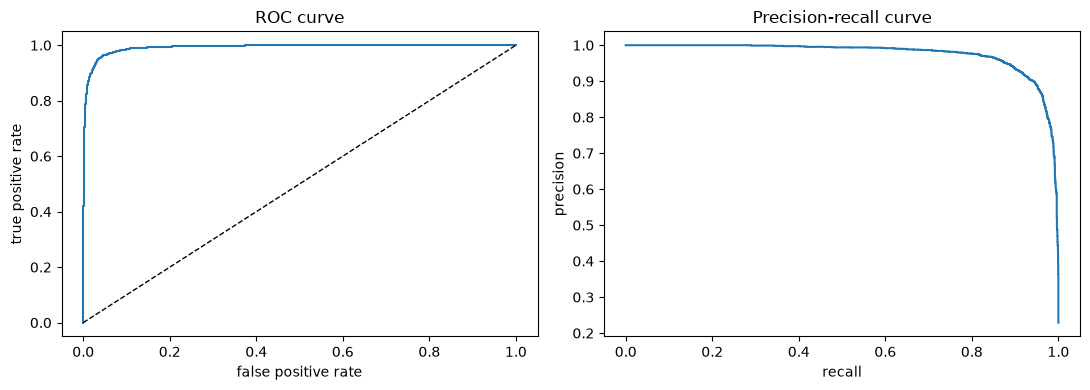

In [16]:
fpr, tpr, _ = roc_curve(y_test, ebm_score)
prec, rec, _ = precision_recall_curve(y_test, ebm_score)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(fpr, tpr)
axes[0].plot([0, 1], [0, 1], 'k--', lw=1)
axes[0].set(xlabel='false positive rate', ylabel='true positive rate', title='ROC curve')
axes[1].plot(rec, prec)
axes[1].set(xlabel='recall', ylabel='precision', title='Precision-recall curve')
plt.tight_layout()
plt.savefig(FIG_DIR + '/ebm_30d_roc_pr.png', dpi=150)
plt.show()

## 8. Explainability

### 8.1 Feature importance

In [17]:
# mean absolute contribution of each term (log-odds)
imp = pd.Series(ebm_model.term_importances(), index=ebm_model.term_names_).sort_values(ascending=False)
imp.head(15)

all__ratio_last30_first30_mean               0.828141
all__last30_share                            0.776861
app_youtube__ratio_last30_first30            0.651731
pack_data__ratio_last30_first30              0.640418
app_facebook__ratio_last30_first30           0.619794
app_other__ratio_last30_first30              0.608121
app_tiktok__ratio_last30_first30             0.595191
all__total                                   0.532556
app_helakuru__ratio_last30_first30           0.485477
pack_vas__ratio_last30_first30               0.481780
voice_d2d_incoming__ratio_last30_first30     0.472235
voice_d2d_outgoing__ratio_last30_first30     0.458830
app_whatsapp__ratio_last30_first30           0.442303
voice_nd2d_incoming__ratio_last30_first30    0.408716
all__days_since_active_mean                  0.405705
dtype: float64

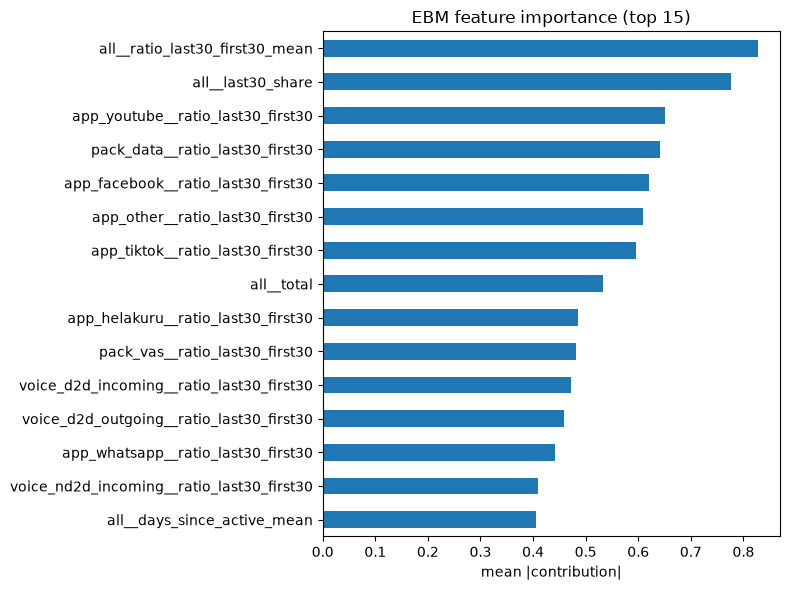

In [18]:
imp.head(15)[::-1].plot.barh(figsize=(8, 6))
plt.xlabel('mean |contribution|')
plt.title('EBM feature importance (top 15)')
plt.tight_layout()
plt.savefig(FIG_DIR + '/ebm_30d_importance.png', dpi=150)
plt.show()

### 8.2 Shape functions

How each feature changes the churn log-odds. Above 0 = more likely to churn.

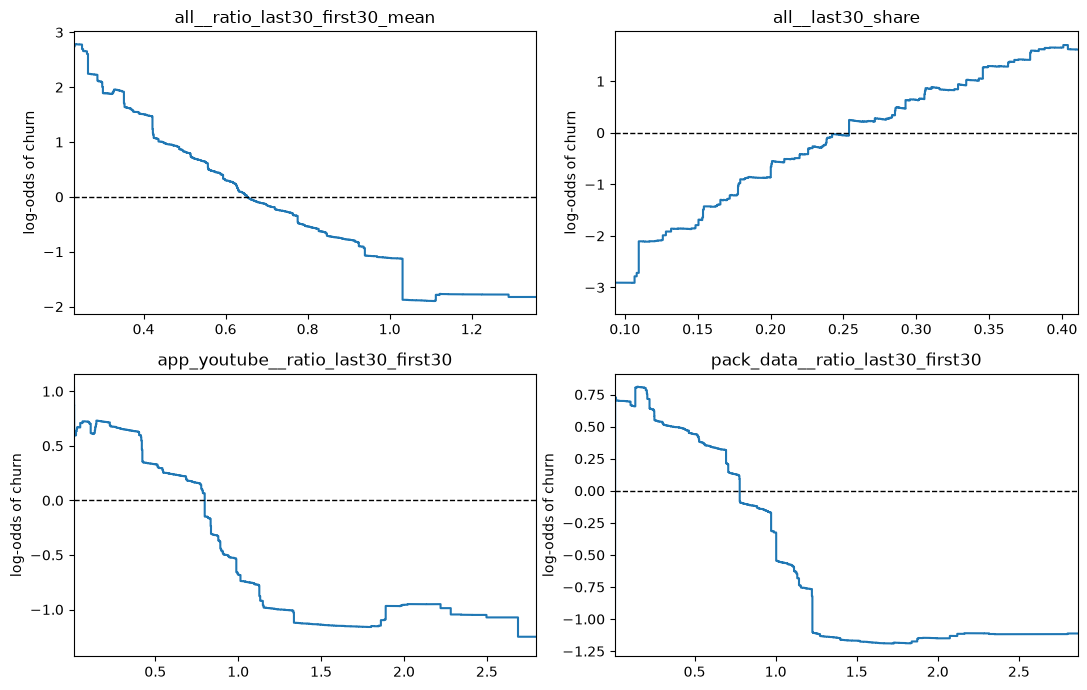

In [19]:
glob = ebm_model.explain_global()
top4 = [n for n in imp.index if ' & ' not in n][:4]

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, name in zip(axes.flat, top4):
    d = glob.data(ebm_model.term_names_.index(name))
    ax.step(d['names'][:-1], d['scores'], where='post')
    ax.axhline(0, color='k', ls='--', lw=1)
    ax.set_xlim(X_train[name].quantile(0.01), X_train[name].quantile(0.99))  # hide outliers
    ax.set(title=name, ylabel='log-odds of churn')
plt.tight_layout()
plt.savefig(FIG_DIR + '/ebm_30d_shape_functions.png', dpi=150)
plt.show()

### 8.3 Single predictions

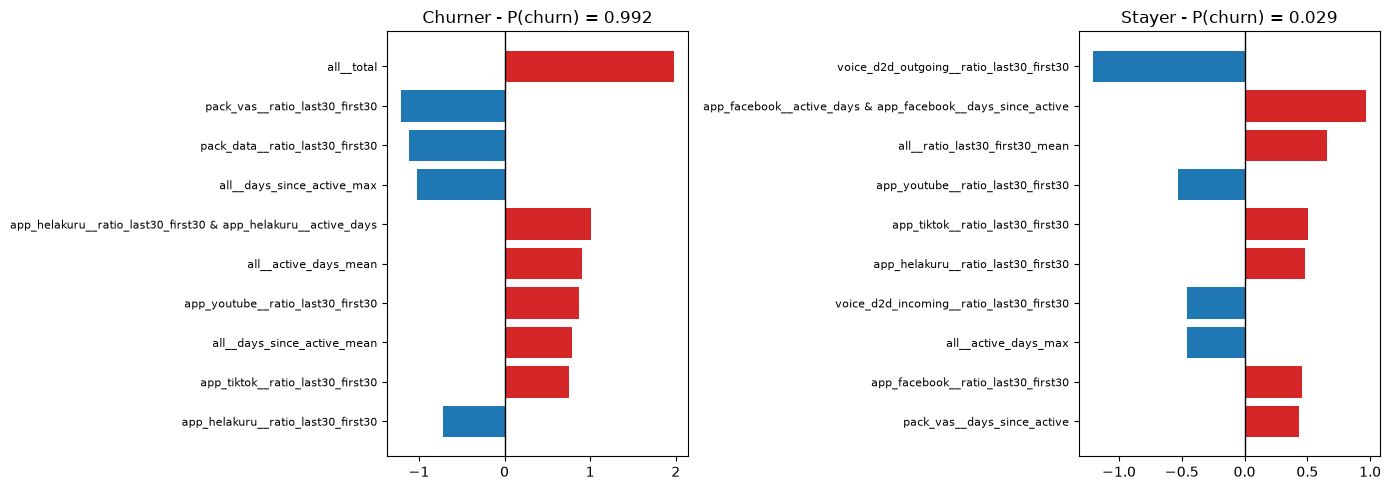

In [20]:
# one churner and one stayer from the test set
churner = np.where((y_test == 1) & (ebm_pred == 1))[0][0]
stayer = np.where((y_test == 0) & (ebm_pred == 0))[0][0]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, i, title in [(axes[0], churner, 'Churner'), (axes[1], stayer, 'Stayer')]:
    d = ebm_model.explain_local(X_test.iloc[[i]]).data(0)
    s = pd.Series(d['scores'], index=d['names'])
    top = s[s.abs().sort_values(ascending=False).index[:10]][::-1]
    ax.barh(top.index, top.values, color=['tab:red' if v > 0 else 'tab:blue' for v in top.values])
    ax.axvline(0, color='k', lw=1)
    ax.set_title(f'{title} - P(churn) = {ebm_score[i]:.3f}')
    ax.tick_params(axis='y', labelsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR + '/ebm_30d_local.png', dpi=150)
plt.show()

## 9. Interpretation

- **Results:** using only the first 30 days, the model gets ROC-AUC 0.992 and F1 0.919 on the test set. It catches 91% of churners (recall 0.910) and 93% of the customers it flags really churn (precision 0.928).
- **Tuning:** the default model overfits (train F1 0.966 vs validation 0.917). The tuned model (larger leaves, 20 interactions) narrows the gap (0.948 vs 0.921) and is slightly better on validation.
- **Main features:** the overall usage trend in the month (days 21-30 vs days 1-10) is the most important, followed by the trends of single services (YouTube, data packs, Facebook) and total usage.
- **Shape functions:** churn risk goes up as the trend goes down. The risk becomes positive below a trend of about 0.65, and services that drop below about 0.8 add to the risk.
- **`all__last30_share`:** the plot shows a higher share as *more* risky. This is not a real effect. The feature is strongly correlated with the trend ratio (0.75), so the model uses it to correct the trend term. The two should be read together.
- **Single predictions:** the churner has low total usage and falling YouTube and TikTok use. For the stayer, growing outgoing calls outweigh the small drops in some apps.
- **Limitation:** customers who only start to drop off after day 30 cannot be caught with this window.

## 10. Save model

In [21]:
path = MODEL_DIR + '/ebm_churn_30d.joblib'
joblib.dump(ebm_model, path)

info = {
    'model': 'ebm_churn_30d',
    'trained_at': datetime.now().isoformat(timespec='seconds'),
    'window_days': 30,
    'n_train': len(X_train),
    'feature_columns': feature_cols,
    'best_params': {k: (v if isinstance(v, (int, float, str)) else str(v)) for k, v in best_params.items()},
    'test_metrics': {k: round(float(v), 4) for k, v in ebm_metrics.items()},
}
with open(MODEL_DIR + '/ebm_churn_30d_info.json', 'w') as f:
    json.dump(info, f, indent=2)
print('saved', path)

saved ../models/ebm_churn_30d.joblib


In [22]:
# check saved model loads ok
ebm_loaded = joblib.load(path)
print((ebm_loaded.predict(X_test) == ebm_pred).all())

True
